# Robot Condition Classification

**Tujuan.** Prediksi kondisi dominan pada setiap baris telemetri robot simulasi. Kelasnya adalah `normal`, `motor_fault`, `wheel_slip`, dan `sensor_fault`. Setiap baris merupakan observasi independen menurut data dictionary. Skor kompetisi adalah rata-rata F1 keempat kelas dengan bobot yang sama.

\[
F1_k = \frac{2TP_k}{2TP_k + FP_k + FN_k},\qquad
\operatorname{MacroF1} = \tfrac14\sum_{k=1}^{4}F1_k.
\]

Kaggle menilai seluruh file prediksi menggunakan label yang disembunyikan. Skor publik menggunakan 30% sampel uji. Skor privat yang menentukan peringkat menggunakan 70% sisanya. Notebook ini mengukur hasil pada data latih berlabel, termasuk holdout lokal. Skor baseline dosen yang dilaporkan, **0,688**, berasal dari leaderboard publik dan memakai sampel evaluasi yang berbeda dari validasi notebook.

**Cara menjalankan.** Letakkan notebook bersama `train.csv`, `test.csv`, dan `sample_submission.csv` atau `sample_submission(1).csv`. Di Kaggle, tambahkan data kompetisi sebagai input notebook. Jika folder berbeda, isi `DATA_DIR` pada sel pertama. Pilih kernel Python 3, lalu jalankan semua sel dari atas. Notebook memakai CPU. Bagian 6 menghasilkan `submission.csv` di direktori kerja Jupyter atau `/kaggle/working` pada Kaggle.

Notebook memakai `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `threadpoolctl`, dan kernel Jupyter `ipykernel`. Versi yang dipakai tercetak pada sel konfigurasi.

## 1. Konfigurasi dan file input

Konteks operasi terdiri dari medan, tipe penggerak, kecepatan perintah, muatan, dan suhu lingkungan. Sembilan variabel lain merekam respons motor, gerak roda, kualitas sensor, atau kondisi baterai. Gunakan hanya 14 kolom yang tercantum sebagai fitur. `Id` dipakai untuk verifikasi data dan pencocokan baris submission.

In [1]:
import hashlib
import os
import platform
from importlib.metadata import version
from itertools import product
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter

SEED = 42
HOLDOUT_FRACTION = 0.20
N_FOLDS = 5
N_REPEATS = 2
CPU_THREADS = 2
DATA_DIR = None  # Contoh: Path(r"D:/Kaggle/Robot_Condition")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(CPU_THREADS))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.special import softmax
from scipy.stats import multivariate_normal
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted
from threadpoolctl import threadpool_limits

TARGET = "fault_type"
LABELS = np.array(["normal", "motor_fault", "wheel_slip", "sensor_fault"])
CATEGORICAL = ["terrain", "robot_type"]
CONTEXT_NUMERIC = ["commanded_speed_mps", "payload_kg", "ambient_temp_c"]
CONTEXT = CATEGORICAL + CONTEXT_NUMERIC
SENSORS = [
    "motor_current_a", "motor_temp_c", "vibration_rms", "wheel_slip_ratio",
    "odom_residual_m", "imu_yaw_std", "lidar_quality", "battery_voltage_v",
    "encoder_disagreement",
]
NUMERIC = CONTEXT_NUMERIC + SENSORS
FEATURES = CATEGORICAL + NUMERIC
RESIDUALS = ["residual_" + sensor for sensor in SENSORS]
TEMPLATE_NAMES = ("sample_submission.csv", "sample_submission(1).csv")
SLUG = "robot-condition-classification-challenge"
KAGGLE_WORK = Path("/kaggle/working")
OUTPUT_DIR = KAGGLE_WORK if KAGGLE_WORK.is_dir() else Path.cwd()


def find_input_dir():
    override = DATA_DIR or os.environ.get("ROBOT_DATA_DIR")
    if override:
        candidates = [Path(override).expanduser()]
    else:
        candidates = [
            Path.cwd(), Path.cwd() / "upload",
            Path("/kaggle/input") / SLUG,
            Path("/kaggle/input/competitions") / SLUG,
        ]
    for directory in candidates:
        if (all((directory / name).is_file() for name in ("train.csv", "test.csv"))
                and any((directory / name).is_file() for name in TEMPLATE_NAMES)):
            return directory
    raise FileNotFoundError(
        "CSV belum ditemukan. Isi DATA_DIR dengan folder yang berisi train.csv, "
        "test.csv, dan sample_submission.csv atau sample_submission(1).csv."
    )


def require_columns(frame, expected, filename):
    if set(frame.columns) != set(expected) or len(frame.columns) != len(expected):
        raise ValueError(f"Kolom {filename} tidak sesuai: {frame.columns.tolist()}")


def check_ids(frame, filename):
    if frame["Id"].isna().any() or not frame["Id"].is_unique:
        raise ValueError(f"Id kosong atau duplikat pada {filename}.")


def check_numeric_features(frame, filename):
    if not all(pd.api.types.is_numeric_dtype(frame[column]) for column in NUMERIC):
        raise ValueError(f"Kolom numerik pada {filename} harus berisi angka atau nilai kosong.")
    if np.isinf(frame[NUMERIC].to_numpy()).any():
        raise ValueError(f"Terdapat nilai tak hingga pada {filename}.")


def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


input_dir = find_input_dir()
train_path = input_dir / "train.csv"
train = pd.read_csv(train_path)
require_columns(train, ["Id", *FEATURES, TARGET], train_path.name)
check_ids(train, train_path.name)
check_numeric_features(train, train_path.name)
if set(train[TARGET]) != set(LABELS):
    raise ValueError("Label train.csv harus lengkap dan sesuai empat kelas kompetisi.")

print(f"Python {platform.python_version()} | {platform.system()} | {CPU_THREADS} thread komputasi")
for package in ("numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "threadpoolctl", "ipykernel"):
    print(f"{package} {version(package)}")
print(f"Data latih: {len(train):,} baris, {len(FEATURES)} fitur")
print(f"SHA-256 {train_path.name}: {file_hash(train_path)}")

Python 3.12.14 | Linux | 2 thread komputasi
numpy 2.3.5
pandas 2.2.3
scipy 1.17.0
scikit-learn 1.8.0
matplotlib 3.10.8
threadpoolctl 3.6.0
ipykernel 7.4.0
Data latih: 7,919 baris, 14 fitur
SHA-256 train.csv: 67a82e148b6169702940bc52b35a0f9b4dfd92f75940d32cfba84b0f4615acc9


## 2. Pembagian data latih dan eksplorasi

Sisihkan **20% dari `train.csv`** sebagai holdout lokal berstratifikasi. Selama eksplorasi dan pemilihan model, gunakan bagian pengembangan. Dua pengulangan validasi silang 5-fold memakai seed 42 dan 43, serta pembagian yang sama untuk semua model. Setiap fold mempertahankan proporsi kelas. Nilai median, skala, encoding, dan referensi sensor yang dipelajari harus difit di bagian latih fold melalui pipeline atau estimator. Setelah pilihan model dikunci, holdout dipakai untuk mengukur performa dan menganalisis kesalahan.

Nilai kosong dapat muncul pada beberapa kanal. Periksa banyaknya baris yang terdampak dan sebaran kelas. Bandingkan median pembacaan sensor sebagai petunjuk untuk membangun model, dengan tetap memeriksa tumpang tindih antar kelas.

In [2]:
X_all = train[FEATURES].copy()
y_all = train[TARGET].copy()

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X_all, y_all, test_size=HOLDOUT_FRACTION, stratify=y_all, random_state=SEED,
)
if X_all.duplicated().any():
    print("Ada fitur yang identik antarbaris. Periksa kemungkinan duplikasi sebelum menginterpretasi skor.")

folds = [
    (repeat + 1, fold + 1, fit_rows, val_rows)
    for repeat in range(N_REPEATS)
    for fold, (fit_rows, val_rows) in enumerate(
        StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + repeat)
        .split(X_dev, y_dev)
    )
]
class_counts = pd.DataFrame({
    "Seluruh train": y_all.value_counts(),
    "Pengembangan": y_dev.value_counts(),
    "Holdout": y_hold.value_counts(),
}).reindex(LABELS)
class_counts["Proporsi train (%)"] = 100 * class_counts["Seluruh train"] / len(y_all)
display(class_counts.round(2))
print(f"Pengembangan: {len(X_dev):,} baris | Holdout: {len(X_hold):,} baris")

,Seluruh train,Pengembangan,Holdout,Proporsi train (%)
fault_type,,,,
normal,5293,4234,1059,66.84
motor_fault,1282,1026,256,16.19
wheel_slip,934,747,187,11.79
sensor_fault,410,328,82,5.18


Pengembangan: 6,335 baris | Holdout: 1,584 baris


,Jumlah kosong,Persen baris
lidar_quality,279,4.40
vibration_rms,183,2.89
motor_temp_c,121,1.91
imu_yaw_std,117,1.85


,Baris dengan fitur kosong (%)
fault_type,
normal,10.86
motor_fault,9.75
wheel_slip,11.11
sensor_fault,7.62


fault_type,normal,motor_fault,wheel_slip,sensor_fault
terrain,,,,
asphalt,1246,306,169,69
gravel,1074,245,199,77
indoor,1324,324,215,113
wet_ground,590,151,164,69


fault_type,normal,motor_fault,wheel_slip,sensor_fault
robot_type,,,,
differential,1723,416,285,132
four_wheel,1195,271,188,86
skid_steer,1316,339,274,110


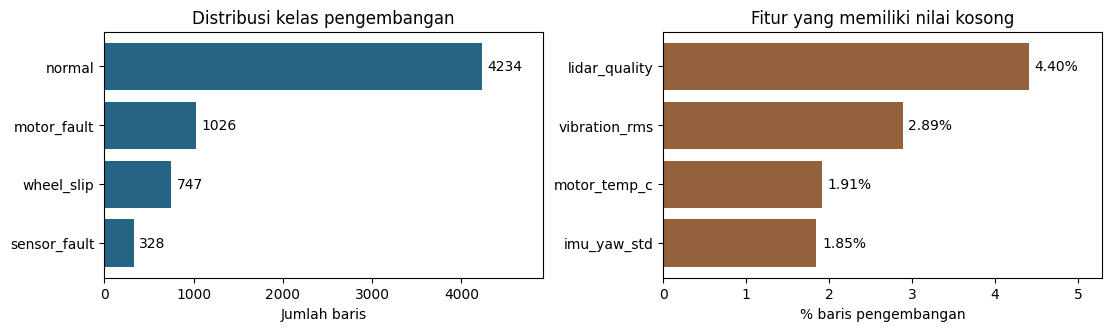

In [3]:
missing = X_dev.isna().sum()
missing = missing[missing.gt(0)].sort_values(ascending=False)
missing_table = missing.to_frame("Jumlah kosong")
missing_table["Persen baris"] = 100 * missing / len(X_dev)
display(missing_table.round(2))
dev_incomplete = X_dev.isna().any(axis=1)
missing_by_class = (100 * dev_incomplete.groupby(y_dev).mean()).reindex(LABELS)
display(missing_by_class.to_frame("Baris dengan fitur kosong (%)").round(2))

for column in CATEGORICAL:
    display(pd.crosstab(X_dev[column], y_dev).reindex(columns=LABELS, fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
class_bar = axes[0].barh(LABELS[::-1], class_counts.loc[LABELS[::-1], "Pengembangan"],
                        color="#256485")
axes[0].bar_label(class_bar, padding=4)
axes[0].margins(x=0.16)
axes[0].set(title="Distribusi kelas pengembangan", xlabel="Jumlah baris")
missing_bar = axes[1].barh(missing_table.index[::-1], missing_table["Persen baris"][::-1],
                          color="#94613d")
axes[1].bar_label(missing_bar, fmt="%.2f%%", padding=4)
axes[1].margins(x=0.20)
axes[1].set(title="Fitur yang memiliki nilai kosong", xlabel="% baris pengembangan")
plt.show()

,motor_current_a,motor_temp_c,wheel_slip_ratio,odom_residual_m,lidar_quality,encoder_disagreement
fault_type,,,,,,
normal,5.0935,52.73,0.0791,0.1267,0.8806,0.0481
motor_fault,7.0650,61.44,0.0832,0.1366,0.8745,0.0532
wheel_slip,5.8410,53.59,0.2826,0.2355,0.8732,0.1200
sensor_fault,4.8675,52.71,0.0869,0.2250,0.6430,0.1340


,count,mean,std,min,5%,50%,95%,max
commanded_speed_mps,6335.0,1.1836,0.5912,0.150,0.2557,1.1910,2.0953,2.2000
payload_kg,6335.0,5.9789,3.4648,0.002,0.6097,5.9500,11.3736,11.9930
ambient_temp_c,6335.0,28.0760,4.5141,16.000,20.6270,28.0400,35.5230,43.0000
motor_current_a,6335.0,5.4903,1.5812,0.178,2.9121,5.4440,8.1628,10.8570
motor_temp_c,6214.0,54.1421,8.7505,25.270,39.7700,54.0500,68.7835,85.1000
vibration_rms,6152.0,0.5551,0.1649,0.020,0.2940,0.5502,0.8332,1.1377
wheel_slip_ratio,6335.0,0.1151,0.1074,0.000,0.0000,0.0963,0.3235,0.6269
odom_residual_m,6335.0,0.1505,0.0898,0.000,0.0000,0.1442,0.3061,0.5213
imu_yaw_std,6218.0,0.0620,0.0520,0.002,0.0020,0.0550,0.1589,0.2655
lidar_quality,6056.0,0.8569,0.1184,0.287,0.6404,0.8706,1.0000,1.0000


,size,median
terrain,,
asphalt,1246,0.0632
gravel,1074,0.0955
indoor,1324,0.0645
wet_ground,590,0.1126


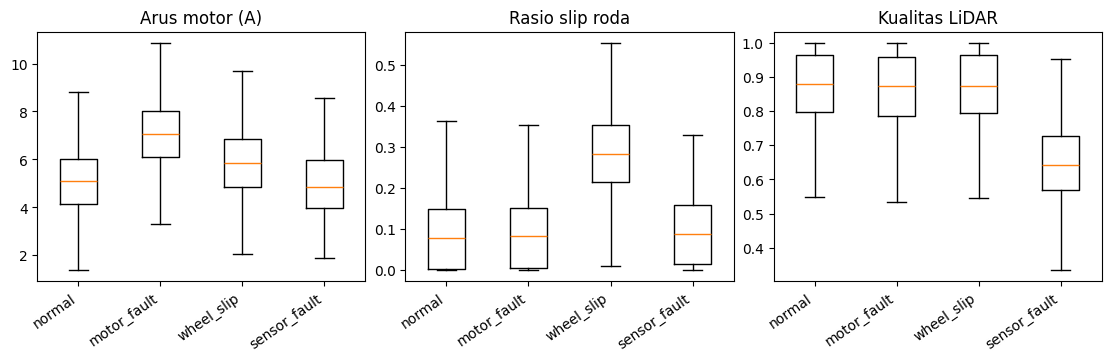

In [4]:
sensor_examples = ["motor_current_a", "motor_temp_c", "wheel_slip_ratio",
                   "odom_residual_m", "lidar_quality", "encoder_disagreement"]
display(X_dev[sensor_examples].groupby(y_dev).median().reindex(LABELS).round(4))
display(X_dev[NUMERIC].describe(percentiles=[0.05, 0.5, 0.95]).T.round(4))

normal_dev = X_dev.loc[y_dev.eq("normal")]
display(normal_dev.groupby("terrain")["wheel_slip_ratio"].agg(["size", "median"]).round(4))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
for ax, field, title in zip(
    axes,
    ["motor_current_a", "wheel_slip_ratio", "lidar_quality"],
    ["Arus motor (A)", "Rasio slip roda", "Kualitas LiDAR"],
):
    values = [X_dev.loc[y_dev.eq(label), field].dropna() for label in LABELS]
    ax.boxplot(values, showfliers=False)
    ax.set_xticks(range(1, len(LABELS) + 1), LABELS, rotation=35, ha="right")
    ax.set_title(title)
plt.show()

Dalam bagian pengembangan, arus dan suhu motor cenderung lebih tinggi pada `motor_fault`. Rasio slip cenderung lebih tinggi pada `wheel_slip`. Kualitas LiDAR cenderung lebih rendah pada `sensor_fault`. Sebaran kelas bertumpang tindih, sehingga keputusan tetap memakai beberapa fitur. Rasio slip pada observasi berlabel `normal` juga berbeda menurut medan. Ini memotivasi pengujian model yang mempertimbangkan konteks operasi.

## 3. Model dan cara menangani sensor kosong

| Konfigurasi | Alasan diuji |
|---|---|
| Logistic Regression | Baseline yang ringan. Numerik memakai imputasi median, indikator kosong, dan scaling. Medan serta tipe robot memakai one-hot encoding. |
| Logistic Regression berbobot | Menguji dampak pembobotan kelas saat fit. Kenaikan recall kelas minoritas bisa disertai penurunan precision. |
| Histogram Gradient Boosting | Menguji interaksi nonlinier. Model dapat menangani nilai numerik kosong secara native. |
| Logistic Regression + residual | Menguji apakah tambahan selisih terhadap nilai sensor yang diperkirakan dalam kondisi normal membantu. |
| Gaussian + prior global | Menguji model distribusi residual dengan prior kelas dari proporsi label pada fold latih. |
| Gaussian + prior konteks | Memperkirakan prior kelas dari kondisi operasi dengan Logistic Regression. Kovarians residual dibagi antarkelas agar estimasinya stabil. |
| Gaussian + prior konteks, kovarians campuran | Memberi bobot 35% pada kovarians khusus kelas dan 65% pada kovarians gabungan untuk menguji apakah sebaran tiap fault membutuhkan fleksibilitas tambahan. |

**Residual sensor.** Untuk setiap kanal, Ridge Regression belajar dari baris `normal` berlabel pada bagian latih yang sedang digunakan. Prediktornya adalah lima variabel konteks yang tersedia pada saat inferensi. Residual adalah nilai yang terbaca dikurangi nilai yang diperkirakan. Contohnya, arus tinggi dengan muatan berat dapat menghasilkan residual lebih kecil dibandingkan arus yang sama pada muatan ringan. Kanal yang kosong tetap kosong pada tahap ini.

**Model Gaussian.** Kelas diberi skor menggunakan log prior dan log densitas residual pada kanal yang tersedia. Kovarians gabungan mempertahankan hubungan antarkanal dan menstabilkan estimasi dari kelas kecil. Penambahan kecil pada diagonal menjaga kovarians definit positif. Ketika LiDAR kosong, skor memakai rerata dan submatriks kovarians dari kanal yang masih teramati. Ini adalah marginal Gaussian. Pendekatan ini mengasumsikan residual mendekati Gaussian dan memakai pola nilai kosong hanya untuk memilih kanal yang tersedia. Pola kosong yang berkaitan langsung dengan suatu fault dapat mengandung informasi tambahan pada sistem lain.

\[
\log s_k = \log P(k\mid\mathrm{konteks}) +
\log\mathcal{N}(r_{\mathrm{teramati}};\mu_{k,\mathrm{teramati}},\Sigma_{k,\mathrm{teramati}}).
\]

In [5]:
def encode_categories():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)


def scale_context():
    return ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
         CONTEXT_NUMERIC),
        ("category", encode_categories(), CATEGORICAL),
    ])


class NormalSensorReference(TransformerMixin, BaseEstimator):
    def fit(self, X, y):
        healthy = X.loc[np.asarray(y) == "normal", :]
        self.encoder_ = scale_context()
        context = self.encoder_.fit_transform(healthy[CONTEXT])
        self.references_ = {}
        for sensor in SENSORS:
            observed = healthy[sensor].notna().to_numpy()
            model = Ridge(alpha=1.0)
            self.references_[sensor] = model.fit(context[observed], healthy.loc[observed, sensor])
        return self

    def transform(self, X):
        check_is_fitted(self, "references_")
        result = X.copy()
        context = self.encoder_.transform(X[CONTEXT])
        for sensor, model in self.references_.items():
            result["residual_" + sensor] = X[sensor] - model.predict(context)
        return result


def logistic_pipeline(class_weight=None, add_residuals=False):
    numeric = NUMERIC + RESIDUALS if add_residuals else NUMERIC
    preprocess = ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                  StandardScaler()), numeric),
        ("category", encode_categories(), CATEGORICAL),
    ])
    classifier = LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=SEED)
    if add_residuals:
        return make_pipeline(NormalSensorReference(), preprocess, classifier)
    return make_pipeline(preprocess, classifier)


def boosting_pipeline():
    preprocess = ColumnTransformer([
        ("numeric", "passthrough", NUMERIC),
        ("category", encode_categories(), CATEGORICAL),
    ])
    return make_pipeline(preprocess, HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.065, max_leaf_nodes=15, min_samples_leaf=24,
        l2_regularization=2.0, early_stopping=False, random_state=SEED,
    ))

In [6]:
class ResidualGaussian(ClassifierMixin, BaseEstimator):
    def __init__(self, contextual_prior=True, covariance_mix=0.0):
        self.contextual_prior = contextual_prior
        self.covariance_mix = covariance_mix

    def fit(self, X, y):
        labels = np.asarray(y)
        self.classes_, counts = np.unique(labels, return_counts=True)
        self.priors_ = counts / counts.sum()
        self.reference_ = NormalSensorReference().fit(X, y)
        residuals = self.reference_.transform(X)[RESIDUALS]
        self.scales_ = residuals.std().clip(lower=1e-8)
        standardized = residuals / self.scales_

        blocks = [standardized.loc[labels == label] for label in self.classes_]
        self.means_ = np.stack([block.mean().to_numpy() for block in blocks])
        # pandas.cov menghitung pasangan kanal dari baris yang keduanya teramati.
        covariances = np.stack([block.cov().to_numpy() for block in blocks])
        pooled = np.average(covariances, axis=0, weights=counts - 1)
        self.covariances_ = (
            (1 - self.covariance_mix) * pooled + self.covariance_mix * covariances
        )
        identity = np.eye(len(SENSORS))
        for covariance in self.covariances_:
            min_eigenvalue = np.linalg.eigvalsh(covariance)[0]
            covariance += max(0.03, 0.03 - min_eigenvalue) * identity

        self.prior_model_ = None
        if self.contextual_prior:
            self.prior_model_ = make_pipeline(
                scale_context(), LogisticRegression(max_iter=1000, random_state=SEED)
            )
            self.prior_model_.fit(X[CONTEXT], labels)
        return self

    def predict_proba(self, X):
        check_is_fitted(self, "covariances_")
        residuals = self.reference_.transform(X)[RESIDUALS]
        standardized = (residuals / self.scales_).to_numpy()
        if self.prior_model_ is None:
            priors = np.broadcast_to(self.priors_, (len(X), len(self.classes_)))
        else:
            priors = self.prior_model_.predict_proba(X[CONTEXT])

        scores = np.log(priors.clip(min=1e-12))
        # Satu marginal Gaussian per pola kanal yang teramati.
        masks, groups = np.unique(np.isfinite(standardized), axis=0, return_inverse=True)
        for group, observed in enumerate(masks):
            if not observed.any():
                continue
            rows = groups == group
            values = standardized[rows][:, observed]
            for k, (mean, covariance) in enumerate(zip(self.means_, self.covariances_)):
                scores[rows, k] += multivariate_normal.logpdf(
                    values, mean=mean[observed], cov=covariance[np.ix_(observed, observed)]
                )
        return softmax(scores, axis=1)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


models = {
    "Logistic Regression (baseline)": logistic_pipeline(),
    "Logistic Regression berbobot": logistic_pipeline(class_weight="balanced"),
    "Histogram Gradient Boosting": boosting_pipeline(),
    "Logistic Regression + residual": logistic_pipeline(add_residuals=True),
    "Gaussian + prior global": ResidualGaussian(contextual_prior=False),
    "Gaussian + prior konteks": ResidualGaussian(),
    "Gaussian + prior konteks, kovarians campuran": ResidualGaussian(covariance_mix=0.35),
}
BASELINE = next(iter(models))


def probabilities(model, X):
    # Urutan kelas estimator bisa berbeda dari urutan laporan.
    positions = [list(model.classes_).index(label) for label in LABELS]
    return model.predict_proba(X)[:, positions]


def decide(probability, multipliers):
    return LABELS[np.argmax(probability * multipliers, axis=1)]


def macro_f1(actual, predicted):
    return f1_score(actual, predicted, labels=LABELS, average="macro", zero_division=0)


def class_metrics(actual, predicted):
    precision, recall, f1, support = precision_recall_fscore_support(
        actual, predicted, labels=LABELS, zero_division=0
    )
    return pd.DataFrame(
        {"Precision": precision, "Recall": recall, "F1": f1, "Support": support},
        index=pd.Index(LABELS, name="Kelas"),
    )

## 4. Validasi silang dan pemilihan model

Setiap kandidat diuji pada sepuluh fold validasi. Prediksi pada setiap fold berasal dari model yang belum melihat label fold itu. Bandingkan mean dan simpangan baku Macro-F1, F1 per kelas, serta waktu fit dan inferensi. F1 per kelas dihitung dari seluruh prediksi validasi dalam satu pengulangan dan dirata-ratakan antar pengulangan. Simpangan baku antar-fold menggambarkan variasi skor pada pembagian ini.

Urutkan model menurut mean Macro-F1 dengan aturan probabilitas tertinggi. Pada model terbaik, uji penyesuaian ringan dengan mengalikan probabilitas masing-masing kelas fault dengan 0,85, 1,00, atau 1,15. Pilih konfigurasi yang menaikkan mean setidaknya 0,001 dan meningkatkan mean di **kedua** pengulangan. Pertahankan faktor 1,00 jika syarat itu tidak tercapai. Faktor hanya digunakan untuk keputusan akhir. Setelah penyesuaian, nilainya tidak lagi dibaca sebagai probabilitas terkalibrasi.

Penyetelan ini memakai prediksi validasi pengembangan, sehingga skor hasil penyetelan pada fold yang sama bisa optimistis. Holdout lokal memberikan pemeriksaan setelah pilihan dikunci.

Pembanding semua normal: accuracy=0.6684, Macro-F1=0.2003


,mean_f1,sd_f1,min_f1,mean_fit_s,mean_prediksi_s,F1 normal,F1 motor_fault,F1 wheel_slip,F1 sensor_fault
Model,,,,,,,,,
Gaussian + prior konteks,0.8204,0.0116,0.7981,0.0420,0.0132,0.9268,0.7900,0.8359,0.7294
"Gaussian + prior konteks, kovarians campuran",0.8185,0.0103,0.8012,0.0409,0.0132,0.9271,0.7936,0.8349,0.7190
Gaussian + prior global,0.8178,0.0094,0.8017,0.0247,0.0110,0.9259,0.7870,0.8349,0.7244
Logistic Regression + residual,0.8126,0.0111,0.7951,0.0663,0.0086,0.9261,0.7962,0.8407,0.6883
Logistic Regression (baseline),0.8103,0.0119,0.7897,0.0320,0.0030,0.9248,0.7889,0.8397,0.6888
Histogram Gradient Boosting,0.7777,0.0106,0.7631,1.1095,0.0381,0.9128,0.7469,0.8074,0.6442
Logistic Regression berbobot,0.7608,0.0080,0.7510,0.0254,0.0028,0.8775,0.7498,0.8033,0.6119


Model             Gaussian + prior konteks  \
Pengulangan Fold                             
1           1                       0.8169   
            2                       0.8272   
            3                       0.8366   
            4                       0.8051   
            5                       0.8216   
2           1                       0.8289   
            2                       0.7981   
            3                       0.8170   
            4                       0.8282   
            5                       0.8239   

Model             Gaussian + prior konteks, kovarians campuran  \
Pengulangan Fold                                                 
1           1                                           0.8118   
            2                                           0.8295   
            3                                           0.8279   
            4                                           0.8023   
            5                                           0.8200   
2           1                                           0.8271   
            2                                           0.8012   
            3                                           0.8178   
            4                                           0.8259   
            5                                           0.8214   

Model             Gaussian + prior global  Logistic Regression + residual  \
Pengulangan Fold                                                            
1           1                      0.8210                          0.7989   
            2                      0.8299                          0.8261   
            3                      0.8246                          0.8237   
            4                      0.8031                          0.8042   
            5                      0.8128                          0.8115   
2           1                      0.8247                          0.8219   
            2                      0.8017                          0.7951   
            3                      0.8194                          0.8096   
            4                      0.8247                          0.8242   
            5                      0.8158                          0.8112   

Model             Logistic Regression (baseline)  Histogram Gradient Boosting  \
Pengulangan Fold                                                                
1           1                             0.7985                       0.7844   
            2                             0.8253                       0.7709   
            3                             0.8183                       0.7808   
            4                             0.8020                       0.7683   
            5                             0.8137                       0.7800   
2           1                             0.8160                       0.8013   
            2                             0.7897                       0.7631   
            3                             0.8102                       0.7754   
            4                             0.8265                       0.7721   
            5                             0.8034                       0.7807   

Model             Logistic Regression berbobot  
Pengulangan Fold                                
1           1                           0.7545  
            2                           0.7603  
            3                           0.7679  
            4                           0.7534  
            5                           0.7584  
2           1                           0.7694  
            2                           0.7736  
            3                           0.7510  
            4                           0.7664  
            5                           0.7533

,Precision,Recall,F1
Model untuk sensor_fault,,,
Logistic Regression (baseline),0.7559,0.6326,0.6888
Logistic Regression berbobot,0.4779,0.8506,0.6119
Gaussian + prior konteks,0.7583,0.7027,0.7294


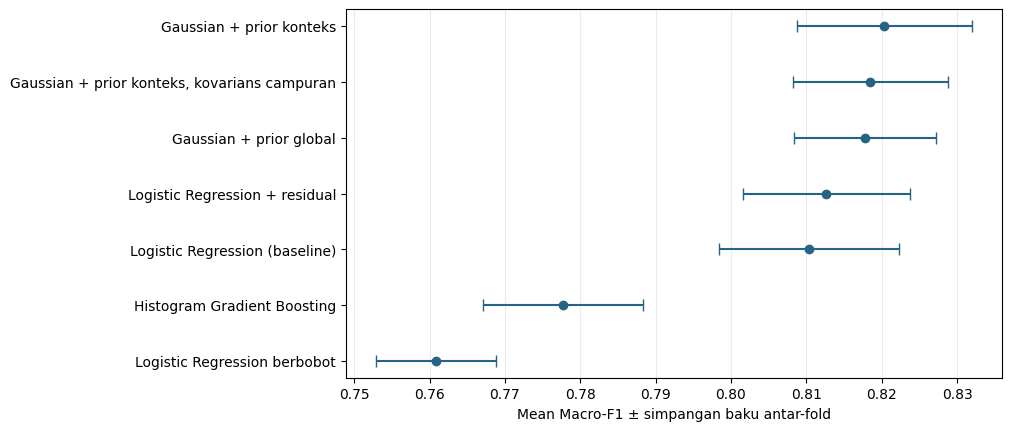

In [7]:
unit_multipliers = np.ones(len(LABELS))
cv_rows = []
cv_predictions = {}
dev_reference = np.asarray(y_dev)
dummy_pred = np.full(len(y_dev), "normal")
print(f"Pembanding semua normal: accuracy={accuracy_score(y_dev, dummy_pred):.4f}, "
      f"Macro-F1={macro_f1(y_dev, dummy_pred):.4f}")

with threadpool_limits(limits=CPU_THREADS):
    for name, prototype in models.items():
        repeat_probabilities = np.empty((N_REPEATS, len(y_dev), len(LABELS)))
        for repeat, fold, fit_rows, val_rows in folds:
            estimator = clone(prototype)
            started = perf_counter()
            estimator.fit(X_dev.iloc[fit_rows], y_dev.iloc[fit_rows])
            fit_time = perf_counter() - started
            started = perf_counter()
            prob = probabilities(estimator, X_dev.iloc[val_rows])
            predict_time = perf_counter() - started

            repeat_probabilities[repeat - 1, val_rows] = prob
            score = macro_f1(dev_reference[val_rows], decide(prob, unit_multipliers))
            cv_rows.append({
                "Model": name, "Pengulangan": repeat, "Fold": fold, "Macro-F1": score,
                "Fit (s)": fit_time, "Prediksi (s)": predict_time,
            })
        cv_predictions[name] = repeat_probabilities

cv = pd.DataFrame(cv_rows)
summary = cv.groupby("Model", sort=False).agg(
    mean_f1=("Macro-F1", "mean"),
    sd_f1=("Macro-F1", "std"),
    min_f1=("Macro-F1", "min"),
    mean_fit_s=("Fit (s)", "mean"),
    mean_prediksi_s=("Prediksi (s)", "mean"),
)
for name, repeat_probabilities in cv_predictions.items():
    repeat_metrics = [
        class_metrics(y_dev, decide(prob, unit_multipliers))["F1"]
        for prob in repeat_probabilities
    ]
    summary.loc[name, ["F1 " + label for label in LABELS]] = (
        pd.concat(repeat_metrics, axis=1).mean(axis=1).to_numpy()
    )
summary = summary.sort_values(["mean_f1", "sd_f1"], ascending=[False, True], kind="stable")
display(summary.round(4))
display(cv.pivot(index=["Pengulangan", "Fold"], columns="Model", values="Macro-F1")
          .reindex(columns=summary.index).round(4))

sensor_cv = pd.DataFrame({
    name: pd.DataFrame([
        class_metrics(y_dev, decide(prob, unit_multipliers)).loc["sensor_fault"]
        for prob in cv_predictions[name]
    ])[["Precision", "Recall", "F1"]].mean()
    for name in dict.fromkeys((BASELINE, "Logistic Regression berbobot", summary.index[0]))
}).T
display(sensor_cv.rename_axis("Model untuk sensor_fault").round(4))

plot_summary = summary.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
ax.errorbar(plot_summary["mean_f1"], plot_summary.index, xerr=plot_summary["sd_f1"],
            fmt="o", color="#256485", capsize=4)
ax.set(xlabel="Mean Macro-F1 ± simpangan baku antar-fold")
ax.grid(axis="x", alpha=0.25)
plt.show()

In [8]:
selected_name = summary.index[0]
selected_prototype = models[selected_name]
development_probabilities = cv_predictions[selected_name]
untuned_repeat = (
    cv.loc[cv["Model"].eq(selected_name)].groupby("Pengulangan")["Macro-F1"].mean().to_numpy()
)
min_mean_gain = 0.001
decision_grid = []

for factors in product((0.85, 1.0, 1.15), repeat=3):
    multipliers = np.array([1.0, *factors])
    fold_scores = np.array([
        macro_f1(
            dev_reference[val_rows],
            decide(development_probabilities[repeat - 1, val_rows], multipliers),
        )
        for repeat, _, _, val_rows in folds
    ])
    repeat_means = fold_scores.reshape(N_REPEATS, N_FOLDS).mean(axis=1)
    gains = repeat_means - untuned_repeat
    decision_grid.append({
        **dict(zip(LABELS, multipliers)),
        "Mean Macro-F1": fold_scores.mean(),
        "SD Macro-F1": fold_scores.std(ddof=1),
        **{f"Δ pengulangan {i + 1}": gain for i, gain in enumerate(gains)},
        "Perubahan": np.count_nonzero(multipliers != 1.0),
        "Lolos kriteria": gains.mean() >= min_mean_gain and np.all(gains > 0),
    })

decision_results = pd.DataFrame(decision_grid).sort_values(
    ["Mean Macro-F1", "Perubahan", "SD Macro-F1"], ascending=[False, True, True], kind="stable"
)
eligible = decision_results.loc[decision_results["Lolos kriteria"]]
decision = eligible.iloc[0] if not eligible.empty else decision_results.loc[decision_results["Perubahan"].eq(0)].iloc[0]
selected_multipliers = decision[LABELS].to_numpy(dtype=float)
display(decision_results.head(6).round(4))
print(f"Model terpilih: {selected_name}")
print("Faktor keputusan:", dict(zip(LABELS.tolist(), selected_multipliers.tolist())))
print(f"CV sebelum penyesuaian: {untuned_repeat.mean():.4f}")
print(f"CV dengan aturan terpilih: {decision['Mean Macro-F1']:.4f}")

,normal,motor_fault,wheel_slip,sensor_fault,Mean Macro-F1,SD Macro-F1,Δ pengulangan 1,Δ pengulangan 2,Perubahan,Lolos kriteria
22,1.0,1.15,1.00,1.00,0.8222,0.0124,0.0022,0.0016,1,True
19,1.0,1.15,0.85,1.00,0.8212,0.0111,0.0007,0.0009,2,False
25,1.0,1.15,1.15,1.00,0.8211,0.0110,0.0015,0.0000,2,False
23,1.0,1.15,1.00,1.15,0.8205,0.0117,0.0010,-0.0007,2,False
4,1.0,0.85,1.00,1.00,0.8204,0.0111,-0.0008,0.0009,1,False
13,1.0,1.00,1.00,1.00,0.8204,0.0116,0.0000,0.0000,0,False


Model terpilih: Gaussian + prior konteks
Faktor keputusan: {'normal': 1.0, 'motor_fault': 1.15, 'wheel_slip': 1.0, 'sensor_fault': 1.0}
CV sebelum penyesuaian: 0.8204
CV dengan aturan terpilih: 0.8222


## 5. Holdout lokal dan analisis kesalahan

Fit ulang model terpilih pada seluruh bagian pengembangan. Gunakan holdout sekali untuk mengukur hasil keputusan yang sudah dikunci. Baseline juga dievaluasi pada holdout yang sama agar selisihnya dapat dilaporkan. Baris confusion matrix adalah kelas sebenarnya dan kolom adalah kelas prediksi. Precision menjawab seberapa sering prediksi suatu kelas benar, sedangkan recall menjawab seberapa banyak anggota kelas tersebut berhasil ditemukan.

Bootstrap berpasangan mengambil ulang baris holdout di dalam tiap kelas. Kedua model dinilai pada sampel bootstrap yang sama. Interval persentil 95% menggambarkan ketidakpastian selisih untuk kedua model yang sudah dilatih, dengan komposisi kelas holdout tetap.

Periksa performa per medan, per tipe robot, dan menurut ketersediaan kanal. Selalu lihat support sebelum menafsirkan angka pada kelompok kecil. Uji tambahan mengosongkan seluruh pembacaan LiDAR pada salinan holdout, sehingga penurunan skor menunjukkan sensitivitas terhadap skenario kanal tersebut gagal total.

Holdout baseline: Macro-F1 0.8231
Holdout model terpilih: Macro-F1 0.8159 | accuracy 0.8851


,Precision,Recall,F1,Support,F1_baseline
Kelas,,,,,
normal,0.9152,0.9377,0.9263,1059,0.9260
motor_fault,0.7948,0.8320,0.8130,256,0.8070
wheel_slip,0.8875,0.7594,0.8184,187,0.8347
sensor_fault,0.7606,0.6585,0.7059,82,0.7248


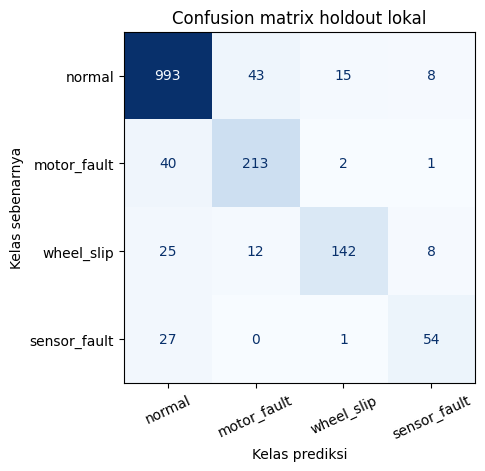

,Aktual,Prediksi,Jumlah
0,normal,motor_fault,43
3,motor_fault,normal,40
9,sensor_fault,normal,27
6,wheel_slip,normal,25
1,normal,wheel_slip,15
7,wheel_slip,motor_fault,12


In [9]:
with threadpool_limits(limits=CPU_THREADS):
    selected_model = clone(selected_prototype).fit(X_dev, y_dev)
    hold_pred = decide(probabilities(selected_model, X_hold), selected_multipliers)
    baseline_model = clone(models[BASELINE]).fit(X_dev, y_dev)
    baseline_hold_pred = decide(probabilities(baseline_model, X_hold), unit_multipliers)

hold_score = macro_f1(y_hold, hold_pred)
hold_baseline_score = macro_f1(y_hold, baseline_hold_pred)
hold_accuracy = accuracy_score(y_hold, hold_pred)
hold_per_class = class_metrics(y_hold, hold_pred)
baseline_per_class = class_metrics(y_hold, baseline_hold_pred)
print(f"Holdout baseline: Macro-F1 {hold_baseline_score:.4f}")
print(f"Holdout model terpilih: Macro-F1 {hold_score:.4f} | accuracy {hold_accuracy:.4f}")
display(hold_per_class.assign(F1_baseline=baseline_per_class["F1"]).round(4))

hold_confusion = confusion_matrix(y_hold, hold_pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(6.3, 4.6), layout="constrained")
ConfusionMatrixDisplay(hold_confusion, display_labels=LABELS).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False, xticks_rotation=25,
)
ax.set(xlabel="Kelas prediksi", ylabel="Kelas sebenarnya", title="Confusion matrix holdout lokal")
plt.show()

errors = pd.DataFrame([
    {"Aktual": actual, "Prediksi": predicted, "Jumlah": hold_confusion[i, j]}
    for i, actual in enumerate(LABELS) for j, predicted in enumerate(LABELS)
    if i != j and hold_confusion[i, j] > 0
], columns=["Aktual", "Prediksi", "Jumlah"]).sort_values("Jumlah", ascending=False, kind="stable")
display(errors.head(6))

In [10]:
actual_hold = y_hold.to_numpy()
class_rows = [np.flatnonzero(actual_hold == label) for label in LABELS]
rng = np.random.default_rng(SEED)
bootstrap_deltas = []
for _ in range(1000):
    rows = np.concatenate([rng.choice(group, size=len(group), replace=True) for group in class_rows])
    bootstrap_deltas.append(
        macro_f1(actual_hold[rows], hold_pred[rows]) - macro_f1(actual_hold[rows], baseline_hold_pred[rows])
    )
delta_interval = np.quantile(bootstrap_deltas, [0.025, 0.975])
print(f"Selisih holdout (terpilih − baseline): {hold_score - hold_baseline_score:+.4f}")
print(f"Interval bootstrap 95%: [{delta_interval[0]:+.4f}, {delta_interval[1]:+.4f}]")

error_data = X_hold.assign(Aktual=actual_hold, Prediksi=hold_pred)
for actual, fields in [
    ("motor_fault", ["motor_current_a", "motor_temp_c", "vibration_rms"]),
    ("sensor_fault", ["lidar_quality", "encoder_disagreement"]),
]:
    focus = error_data.loc[error_data["Aktual"].eq(actual) & error_data["Prediksi"].isin([actual, "normal"])]
    by_prediction = focus.groupby("Prediksi")
    print(f"Median sensor untuk kelas aktual {actual} menurut prediksi")
    display(by_prediction[fields].median().join(by_prediction.size().rename("Jumlah baris")).round(4))

Selisih holdout (terpilih − baseline): -0.0072
Interval bootstrap 95%: [-0.0236, +0.0066]
Median sensor untuk kelas aktual motor_fault menurut prediksi


,motor_current_a,motor_temp_c,vibration_rms,Jumlah baris
Prediksi,,,,
motor_fault,7.4140,62.56,0.7434,213
normal,5.8445,57.20,0.6134,40


Median sensor untuk kelas aktual sensor_fault menurut prediksi


,lidar_quality,encoder_disagreement,Jumlah baris
Prediksi,,,
normal,0.7406,0.1140,27
sensor_fault,0.6258,0.1516,54


In [11]:
def subgroup_metrics(groups, group_name, actual, predicted):
    rows = []
    for group in groups.unique():
        mask = groups.eq(group).to_numpy()
        classes = class_metrics(actual[mask], predicted[mask])
        rows.append({
            "Kelompok": group_name,
            "Nilai": group,
            "n": int(mask.sum()),
            "n sensor_fault": int(classes.loc["sensor_fault", "Support"]),
            "Macro-F1": classes["F1"].mean() if classes["Support"].gt(0).all() else np.nan,
            "Recall sensor_fault": (
                classes.loc["sensor_fault", "Recall"]
                if classes.loc["sensor_fault", "Support"] > 0 else np.nan
            ),
        })
    return pd.DataFrame(rows)


missing_groups = X_hold.isna().any(axis=1).map({True: "Ada nilai kosong", False: "Lengkap"})
subgroups = pd.concat([
    subgroup_metrics(X_hold["terrain"], "Medan", actual_hold, hold_pred),
    subgroup_metrics(X_hold["robot_type"], "Tipe robot", actual_hold, hold_pred),
    subgroup_metrics(missing_groups, "Kelengkapan", actual_hold, hold_pred),
], ignore_index=True)
display(subgroups.sort_values(["Kelompok", "Nilai"]).round(4))

hold_no_lidar = X_hold.assign(lidar_quality=np.nan)
with threadpool_limits(limits=CPU_THREADS):
    no_lidar_pred = decide(probabilities(selected_model, hold_no_lidar), selected_multipliers)
    no_lidar_baseline_pred = decide(probabilities(baseline_model, hold_no_lidar), unit_multipliers)
no_lidar_score = macro_f1(y_hold, no_lidar_pred)
no_lidar_class = class_metrics(y_hold, no_lidar_pred)
no_lidar_baseline_score = macro_f1(y_hold, no_lidar_baseline_pred)
display(pd.DataFrame({
    "Macro-F1 terpilih": [hold_score, no_lidar_score],
    "Macro-F1 baseline": [hold_baseline_score, no_lidar_baseline_score],
    "F1 sensor_fault terpilih": [hold_per_class.loc["sensor_fault", "F1"],
                                 no_lidar_class.loc["sensor_fault", "F1"]],
}, index=["Kondisi asli holdout", "LiDAR seluruhnya dikosongkan"]).round(4))

,Kelompok,Nilai,n,n sensor_fault,Macro-F1,Recall sensor_fault
8,Kelengkapan,Ada nilai kosong,179,15,0.7617,0.6667
7,Kelengkapan,Lengkap,1405,67,0.8177,0.6567
2,Medan,asphalt,444,26,0.7978,0.6154
1,Medan,gravel,401,16,0.8046,0.7500
3,Medan,indoor,491,23,0.8279,0.6522
0,Medan,wet_ground,248,17,0.8172,0.6471
4,Tipe robot,differential,649,34,0.7890,0.5588
6,Tipe robot,four_wheel,442,24,0.8556,0.7083
5,Tipe robot,skid_steer,493,24,0.8169,0.7500


,Macro-F1 terpilih,Macro-F1 baseline,F1 sensor_fault terpilih
Kondisi asli holdout,0.8159,0.8231,0.7059
LiDAR seluruhnya dikosongkan,0.7736,0.7642,0.5481


## 6. Fit final dan ekspor submission

Dengan konfigurasi terpilih yang sama, fit ulang preprocessing dan model pada seluruh `train.csv`. Setelah itu baca fitur `test.csv` untuk inferensi. Gunakan template sebagai acuan urutan dan header. Notebook memeriksa keunikan ID, kecocokan ID dengan data uji, cakupan satu prediksi per ID, dan keabsahan label sebelum menyimpan file. Template dipakai untuk struktur file.

In [12]:
with threadpool_limits(limits=CPU_THREADS):
    started = perf_counter()
    final_model = clone(selected_prototype).fit(X_all, y_all)
    final_fit_time = perf_counter() - started

test_path = input_dir / "test.csv"
template_path = next(input_dir / name for name in TEMPLATE_NAMES if (input_dir / name).is_file())
test = pd.read_csv(test_path)
template = pd.read_csv(template_path)
require_columns(test, ["Id", *FEATURES], test_path.name)
check_numeric_features(test, test_path.name)
if template.columns.tolist() != ["Id", TARGET]:
    raise ValueError("Header template harus persis Id,fault_type.")
check_ids(test, test_path.name)
check_ids(template, template_path.name)
if len(test) != len(template) or set(test["Id"]) != set(template["Id"]):
    raise ValueError("ID template dan test.csv harus mencakup baris yang sama.")
if test["Id"].isin(train["Id"]).any():
    raise ValueError("Ada ID yang sama di train.csv dan test.csv.")

with threadpool_limits(limits=CPU_THREADS):
    started = perf_counter()
    test_pred = decide(probabilities(final_model, test[FEATURES]), selected_multipliers)
    final_predict_time = perf_counter() - started

by_id = pd.Series(test_pred, index=test["Id"])
submission = pd.DataFrame({"Id": template["Id"], TARGET: template["Id"].map(by_id)})
if submission[TARGET].isna().any() or not submission[TARGET].isin(LABELS).all():
    raise ValueError("Submission mengandung label kosong atau di luar daftar kelas.")

output_path = OUTPUT_DIR / "submission.csv"
with TemporaryDirectory(dir=OUTPUT_DIR) as tmp_dir:
    temporary_path = Path(tmp_dir) / output_path.name
    submission.to_csv(temporary_path, index=False, lineterminator="\n")
    pd.testing.assert_frame_equal(pd.read_csv(temporary_path), submission)
    temporary_path.replace(output_path)

print(f"Tersimpan: {output_path.name} | {len(submission):,} baris | {submission.columns.tolist()}")
print(f"Fit final {final_fit_time:.3f} s | Inferensi test {final_predict_time:.3f} s")
print(f"Ukuran tabel train dalam memori: {train.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MiB")
print(f"SHA-256 {test_path.name}: {file_hash(test_path)}")
print(f"SHA-256 {output_path.name}: {file_hash(output_path)}")
display(submission[TARGET].value_counts().reindex(LABELS, fill_value=0).to_frame("Jumlah prediksi"))

Tersimpan: submission.csv | 4,081 baris | ['Id', 'fault_type']
Fit final 0.054 s | Inferensi test 0.027 s
Ukuran tabel train dalam memori: 2.09 MiB
SHA-256 test.csv: 09167eb92f01916ac93e358e90ccc1f1654f1987e94912e9d693e9fbd2d5d139
SHA-256 submission.csv: 2da786f9a2e56eb9b325a01962f7664fc9e99482f1ee295b8e06a674514076cd


,Jumlah prediksi
fault_type,
normal,2840
motor_fault,604
wheel_slip,464
sensor_fault,173


## 7. Ringkasan laporan

Bagian ini menggunakan angka yang dihitung dalam notebook. Waktu komputasi bergantung pada mesin dan versi paket.

In [13]:
top_error_text = "Semua observasi holdout diprediksi dengan benar."
if not errors.empty:
    top_error = errors.iloc[0]
    top_error_text = (
        f"Kesalahan terbanyak adalah `{top_error['Aktual']}` yang terbaca sebagai "
        f"`{top_error['Prediksi']}` ({int(top_error['Jumlah'])} observasi)."
    )
worst_terrain = subgroups.loc[subgroups["Kelompok"].eq("Medan")].sort_values("Macro-F1").iloc[0]
sensor = hold_per_class.loc["sensor_fault"]
display(Markdown(f'''
**Masalah dan data.** Tugasnya klasifikasi multikelas pada {len(train):,} baris telemetri simulasi.
Kelas `sensor_fault` mencakup {100 * y_all.eq("sensor_fault").mean():.2f}% data latih.
Pada bagian pengembangan, {100 * dev_incomplete.mean():.2f}% baris memiliki setidaknya satu fitur kosong.

**Perbandingan.** Baseline Logistic Regression memperoleh mean Macro-F1
**{summary.loc[BASELINE, "mean_f1"]:.4f}** pada validasi silang.
Pembobotan kelas mengubah recall `sensor_fault` dari **{sensor_cv.loc[BASELINE, "Recall"]:.3f}**
menjadi **{sensor_cv.loc["Logistic Regression berbobot", "Recall"]:.3f}** dan precision dari
**{sensor_cv.loc[BASELINE, "Precision"]:.3f}** menjadi **{sensor_cv.loc["Logistic Regression berbobot", "Precision"]:.3f}**.
Mean Macro-F1 model berbobot adalah **{summary.loc["Logistic Regression berbobot", "mean_f1"]:.4f}**.
**{selected_name}** dipilih berdasarkan mean Macro-F1
**{decision["Mean Macro-F1"]:.4f} ± {decision["SD Macro-F1"]:.4f}** setelah menerapkan
aturan keputusan terpilih. Pengukuran itu memakai 2 × 5 fold pada bagian pengembangan.
Rata-rata waktu fit per fold untuk model terpilih {summary.loc[selected_name, "mean_fit_s"]:.3f} detik
dengan {CPU_THREADS} thread. Gradient Boosting membutuhkan
{summary.loc["Histogram Gradient Boosting", "mean_fit_s"]:.3f} detik per fold pada mesin yang sama.

**Holdout.** Macro-F1 model terpilih **{hold_score:.4f}** pada {len(y_hold):,} baris
dibandingkan **{hold_baseline_score:.4f}** untuk baseline pada baris yang sama.
Selisihnya **{hold_score - hold_baseline_score:+.4f}** dengan interval bootstrap 95%
**[{delta_interval[0]:+.4f}, {delta_interval[1]:+.4f}]**. Pilihan model berasal dari hasil CV pengembangan.
Untuk `sensor_fault`, precision **{sensor["Precision"]:.3f}**, recall **{sensor["Recall"]:.3f}**,
dan F1 **{sensor["F1"]:.3f}** dari {int(sensor["Support"])} observasi.
{top_error_text}
Pada kasus `sensor_fault` yang diprediksi `normal`, bandingkan median kualitas LiDAR
dan ketidaksepakatan encoder dengan kasus yang terdeteksi pada tabel bagian 5.
Nilai median tersebut menggambarkan pola pada holdout.

**Sensitivitas.** Di antara medan pada holdout, skor terendah tercatat pada
`{worst_terrain["Nilai"]}` ({worst_terrain["Macro-F1"]:.4f}, n={int(worst_terrain["n"])}).
Saat seluruh LiDAR dihilangkan, Macro-F1 berubah dari **{hold_score:.4f}**
menjadi **{no_lidar_score:.4f}** dan F1 `sensor_fault` menjadi
**{no_lidar_class.loc["sensor_fault", "F1"]:.3f}**. Pada skenario yang sama baseline
memperoleh Macro-F1 **{no_lidar_baseline_score:.4f}**. Uji ini mengukur satu skenario gangguan sensor
pada data simulasi yang sama.
'''))


**Masalah dan data.** Tugasnya klasifikasi multikelas pada 7,919 baris telemetri simulasi.
Kelas `sensor_fault` mencakup 5.18% data latih.
Pada bagian pengembangan, 10.54% baris memiliki setidaknya satu fitur kosong.

**Perbandingan.** Baseline Logistic Regression memperoleh mean Macro-F1
**0.8103** pada validasi silang.
Pembobotan kelas mengubah recall `sensor_fault` dari **0.633**
menjadi **0.851** dan precision dari
**0.756** menjadi **0.478**.
Mean Macro-F1 model berbobot adalah **0.7608**.
**Gaussian + prior konteks** dipilih berdasarkan mean Macro-F1
**0.8222 ± 0.0124** setelah menerapkan
aturan keputusan terpilih. Pengukuran itu memakai 2 × 5 fold pada bagian pengembangan.
Rata-rata waktu fit per fold untuk model terpilih 0.042 detik
dengan 2 thread. Gradient Boosting membutuhkan
1.110 detik per fold pada mesin yang sama.

**Holdout.** Macro-F1 model terpilih **0.8159** pada 1,584 baris
dibandingkan **0.8231** untuk baseline pada baris yang sama.
Selisihnya **-0.0072** dengan interval bootstrap 95%
**[-0.0236, +0.0066]**. Pilihan model berasal dari hasil CV pengembangan.
Untuk `sensor_fault`, precision **0.761**, recall **0.659**,
dan F1 **0.706** dari 82 observasi.
Kesalahan terbanyak adalah `normal` yang terbaca sebagai `motor_fault` (43 observasi).
Pada kasus `sensor_fault` yang diprediksi `normal`, bandingkan median kualitas LiDAR
dan ketidaksepakatan encoder dengan kasus yang terdeteksi pada tabel bagian 5.
Nilai median tersebut menggambarkan pola pada holdout.

**Sensitivitas.** Di antara medan pada holdout, skor terendah tercatat pada
`asphalt` (0.7978, n=444).
Saat seluruh LiDAR dihilangkan, Macro-F1 berubah dari **0.8159**
menjadi **0.7736** dan F1 `sensor_fault` menjadi
**0.548**. Pada skenario yang sama baseline
memperoleh Macro-F1 **0.7642**. Uji ini mengukur satu skenario gangguan sensor
pada data simulasi yang sama.


### Integritas dan keterbatasan

- `Id` berfungsi sebagai kunci pencocokan. Semua statistik yang dipakai model belajar dari bagian latih saat fit. Target digunakan untuk stratifikasi, pembelajaran, dan pengukuran pada data berlabel. Evaluasi Kaggle memerlukan pengunggahan `submission.csv` melalui akun peserta.
- Input diasumsikan bisa diperoleh sebelum prediksi, termasuk estimasi slip roda, residual odometri, dan kualitas LiDAR. Pada robot nyata, verifikasi bagaimana fitur itu dihitung, kapan tersedia, dan apakah menggunakan informasi yang hanya muncul sesudah diagnosis. Uji juga pada robot, sesi, dan kondisi operasi nyata yang terpisah.
- Data berasal dari simulasi kelas. Performa lokal berlaku untuk sampel berlabel yang berasal dari sumber simulasi yang sama. Holdout lokal dan leaderboard publik menggunakan sampel evaluasi yang berbeda. Catat skor publik setelah unggah dan skor atau posisi privat saat dirilis.
- Pengungkapan AI yang dapat disesuaikan dengan kontribusi aktual: *ChatGPT digunakan untuk membantu menyusun dan menjalankan draf notebook, membandingkan kandidat model, serta merapikan penjelasan. Saya memeriksa ulang kode, menjalankan notebook, dan memverifikasi hasil yang saya laporkan.* Pakai kalimat terakhir setelah verifikasi pribadi dilakukan.

### Alur presentasi 5 menit

| Waktu | Isi |
|---|---|
| 0:00–0:40 | Tujuan, empat kelas, dan alasan memakai Macro-F1 pada data timpang. |
| 0:40–1:20 | Distribusi kelas, nilai kosong, dan contoh sinyal yang saling tumpang tindih. |
| 1:20–2:40 | Split, baseline, alternatif, dan cara residual sensor dihitung. Tunjukkan tabel CV. |
| 2:40–4:10 | Tunjukkan confusion matrix, kesalahan paling sering, dan hasil uji tanpa LiDAR. |
| 4:10–5:00 | Tunjukkan file submission, skor Kaggle jika tersedia, keterbatasan data simulasi, dan pengungkapan AI. |

### Referensi metode

- [Macro-F1 di scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)
- [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
- [Pipeline dan pencegahan data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [Penanganan nilai kosong oleh Histogram Gradient Boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html)
- [Densitas Gaussian multivariat di SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.multivariate_normal.html)